In [6]:
import sys
sys.path.append("../src")
import contextlib
import io
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.tsa.stattools import grangercausalitytests
from utils.db import get_engine

GROUPS = {
    "AAPL": "Big tech", "MSFT": "Big tech", "NVDA": "Big tech",
    "JPM": "Banks", "BAC": "Banks", "GS": "Banks",
    "O": "Rate proxies", "NEE": "Rate proxies", "DUK": "Rate proxies",
    "GME": "Meme", "AMC": "Meme",
}

# tylko okres z historią newsów
df = pd.read_sql(
    "SELECT * FROM marts.daily_features WHERE news_count IS NOT NULL ORDER BY ticker, trade_date",
    get_engine(), parse_dates=["trade_date"],
)
df["group"] = df["ticker"].map(GROUPS)
df["excess_pct"] = df["excess_ret"] * 100
df["next_excess_pct"] = df["next_excess_ret"] * 100

# dzień bez newsów traktujemy jako neutralny
df["sent"] = df["sentiment_mean"].fillna(0)

# nietypowa liczba newsów względem poprzednich 20 sesji, bez dnia bieżącego
df["log_news"] = np.log1p(df["news_count"])
baseline = df.groupby("ticker")["log_news"].transform(lambda s: s.shift(1).rolling(20, min_periods=10).mean())
df["abn_news"] = df["log_news"] - baseline
df = df.dropna(subset=["excess_pct", "abn_news"]).reset_index(drop=True)

# standaryzacja w obrębie spółki: współczynnik = efekt ruchu o 1 odchylenie standardowe
for col in ["sent", "abn_news"]:
    df[f"{col}_z"] = df.groupby("ticker")[col].transform(lambda s: (s - s.mean()) / s.std())

df.groupby("ticker").agg(
    sesje=("trade_date", "size"),
    sr_newsow=("news_count", "mean"),
    sr_sentyment=("sent", "mean"),
).round(2)

,sesje,sr_newsow,sr_sentyment
ticker,,,
AAPL,243,47.49,0.01
AMC,243,2.11,-0.04
BAC,243,18.35,0.06
DUK,243,4.32,0.15
GME,243,5.23,-0.03
GS,243,21.40,0.04
JPM,243,28.61,0.02
MSFT,243,49.63,0.03
NEE,243,6.61,0.17


In [7]:
def fit(data: pd.DataFrame, y: str, x: list[str]) -> pd.DataFrame:
    data = data.dropna(subset=[y, *x])
    # efekty stałe spółek, błędy klastrowane po dniu (wspólne szoki rynkowe)
    model = smf.ols(f"{y} ~ {' + '.join(x)} + C(ticker)", data=data).fit(
        cov_type="cluster", cov_kwds={"groups": data["trade_date"].factorize()[0]},
    )
    ci = model.conf_int()

    return pd.DataFrame({
        "beta": model.params,
        "low": ci[0],
        "high": ci[1],
        "p_value": model.pvalues,
        "n": int(model.nobs),
    }).loc[x]


SPECS = {
    "same day": ("excess_pct", ["sent_z", "abn_news_z"]),
    "next day": ("next_excess_pct", ["sent_z", "abn_news_z", "excess_pct"]),
}

results = pd.concat(
    {(group, horizon): fit(part, y, x)
     for group, part in df.groupby("group")
     for horizon, (y, x) in SPECS.items()},
    names=["group", "horizon", "term"],
)

results.round(3)

beta    low   high  p_value    n
group        horizon  term                                         
Banks        same day sent_z      0.213  0.082  0.344    0.001  729
                      abn_news_z -0.069 -0.219  0.081    0.365  729
             next day sent_z     -0.018 -0.120  0.084    0.725  726
                      abn_news_z -0.039 -0.165  0.087    0.543  726
                      excess_pct  0.022 -0.066  0.109    0.623  726
Big tech     same day sent_z      0.254  0.033  0.476    0.024  729
                      abn_news_z -0.028 -0.165  0.108    0.686  729
             next day sent_z     -0.025 -0.168  0.118    0.732  726
                      abn_news_z  0.086 -0.088  0.259    0.332  726
                      excess_pct -0.001 -0.105  0.104    0.991  726
Meme         same day sent_z      0.684  0.314  1.053    0.000  486
                      abn_news_z  0.329 -0.229  0.887    0.247  486
             next day sent_z     -0.159 -0.471  0.154    0.319  484
                      abn_news_z -0.084 -0.454  0.287    0.658  484
                      excess_pct -0.001 -0.136  0.134    0.994  484
Rate proxies same day sent_z      0.033 -0.068  0.134    0.527  729
                      abn_news_z -0.050 -0.179  0.079    0.446  729
             next day sent_z      0.073 -0.035  0.181    0.183  726
                      abn_news_z -0.014 -0.127  0.099    0.809  726
                      excess_pct -0.064 -0.176  0.048    0.263  726

In [8]:
LAGS = 2


def granger_p(data: pd.DataFrame, cause: str, effect: str) -> float:
    with contextlib.redirect_stdout(io.StringIO()):
        res = grangercausalitytests(data[[effect, cause]].dropna(), maxlag=[LAGS])

    return res[LAGS][0]["ssr_ftest"][1]


granger = pd.DataFrame([
    {
        "ticker": ticker,
        "group": GROUPS[ticker],
        "sentiment -> returns": granger_p(g, "sent", "excess_pct"),
        "returns -> sentiment": granger_p(g, "excess_pct", "sent"),
    }
    for ticker, g in df.groupby("ticker")
]).set_index("ticker")

# korekta Benjaminiego-Hochberga na 11 testów w każdym kierunku
for col in ["sentiment -> returns", "returns -> sentiment"]:
    granger[f"{col} (adj.)"] = multipletests(granger[col], method="fdr_bh")[1]

granger.round(3)

,group,sentiment -> returns,returns -> sentiment,sentiment -> returns (adj.),returns -> sentiment (adj.)
ticker,,,,,
AAPL,Big tech,0.502,0.061,0.614,0.167
AMC,Meme,0.300,0.681,0.572,0.832
BAC,Banks,0.796,0.010,0.796,0.106
DUK,Rate proxies,0.463,0.149,0.614,0.329
GME,Meme,0.312,0.793,0.572,0.872
GS,Banks,0.308,0.933,0.572,0.933
JPM,Banks,0.090,0.019,0.494,0.107
MSFT,Big tech,0.225,0.384,0.572,0.536
NEE,Rate proxies,0.733,0.036,0.796,0.131


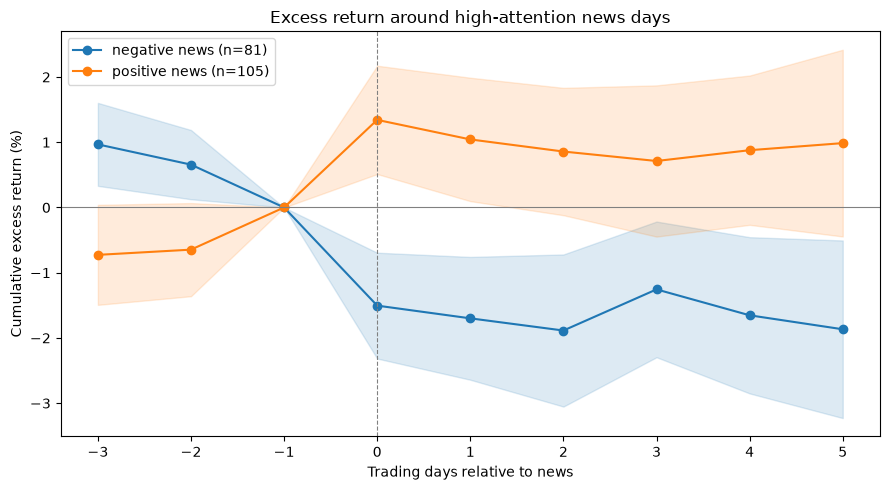

In [9]:
WINDOW = list(range(-3, 6))

for k in WINDOW:
    df[f"ret_{k}"] = df.groupby("ticker")["excess_pct"].shift(-k)

# dzień 0 = pierwsza sesja, w której można było zareagować na news
events = df[df["abn_news_z"] > 1.0]
masks = {
    "negative news": events["sent_z"] < -0.5,
    "positive news": events["sent_z"] > 0.5,
}

fig, ax = plt.subplots(figsize=(9, 5))
for label, mask in masks.items():
    part = events[mask][[f"ret_{k}" for k in WINDOW]].dropna()
    cum = part.cumsum(axis=1)
    cum = cum.sub(cum[f"ret_{WINDOW[WINDOW.index(-1)]}"], axis=0)
    mean = cum.mean()
    se = cum.std() / np.sqrt(len(cum))

    line, = ax.plot(WINDOW, mean.values, marker="o", label=f"{label} (n={len(cum)})")
    ax.fill_between(WINDOW, (mean - 1.96 * se).values, (mean + 1.96 * se).values,
                    color=line.get_color(), alpha=0.15)

ax.axhline(0, color="grey", linewidth=0.8)
ax.axvline(0, color="grey", linestyle="--", linewidth=0.8)
ax.set_xlabel("Trading days relative to news")
ax.set_ylabel("Cumulative excess return (%)")
ax.set_title("Excess return around high-attention news days")
ax.legend()
plt.tight_layout()

docs = Path("../docs")
docs.mkdir(exist_ok=True)
plt.savefig(docs / "news_event_study.png", dpi=150)
plt.show()

In [16]:
TICKER = "MSFT"


def fit_one(data: pd.DataFrame, y: str, x: list[str]) -> pd.DataFrame:
    data = data.dropna(subset=[y, *x])
    # jedna spółka, więc zamiast klastrów po dniu: Newey-West jak w notebooku 01
    model = smf.ols(f"{y} ~ {' + '.join(x)}", data=data).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
    ci = model.conf_int()

    return pd.DataFrame({
        "beta": model.params,
        "low": ci[0],
        "high": ci[1],
        "p_value": model.pvalues,
        "n": int(model.nobs),
    }).loc[x]


def analyse_ticker(ticker: str) -> tuple[pd.DataFrame, pd.Series]:
    data = df[df["ticker"] == ticker]
    regressions = pd.concat(
        {horizon: fit_one(data, y, x) for horizon, (y, x) in SPECS.items()},
        names=["horizon", "term"],
    )
    granger = pd.Series({
        "sentiment -> returns": granger_p(data, "sent", "excess_pct"),
        "returns -> sentiment": granger_p(data, "excess_pct", "sent"),
    }, name="p_value")

    return regressions, granger


regressions, granger_one = analyse_ticker(TICKER)
display(regressions.round(3), granger_one.round(3))

beta    low   high  p_value    n
horizon  term                                         
same day sent_z      0.264 -0.084  0.612    0.137  243
         abn_news_z  0.059 -0.190  0.308    0.643  243
next day sent_z     -0.035 -0.304  0.234    0.800  242
         abn_news_z  0.163 -0.202  0.528    0.381  242
         excess_pct  0.041 -0.119  0.201    0.616  242

sentiment -> returns    0.225
returns -> sentiment    0.384
Name: p_value, dtype: float64

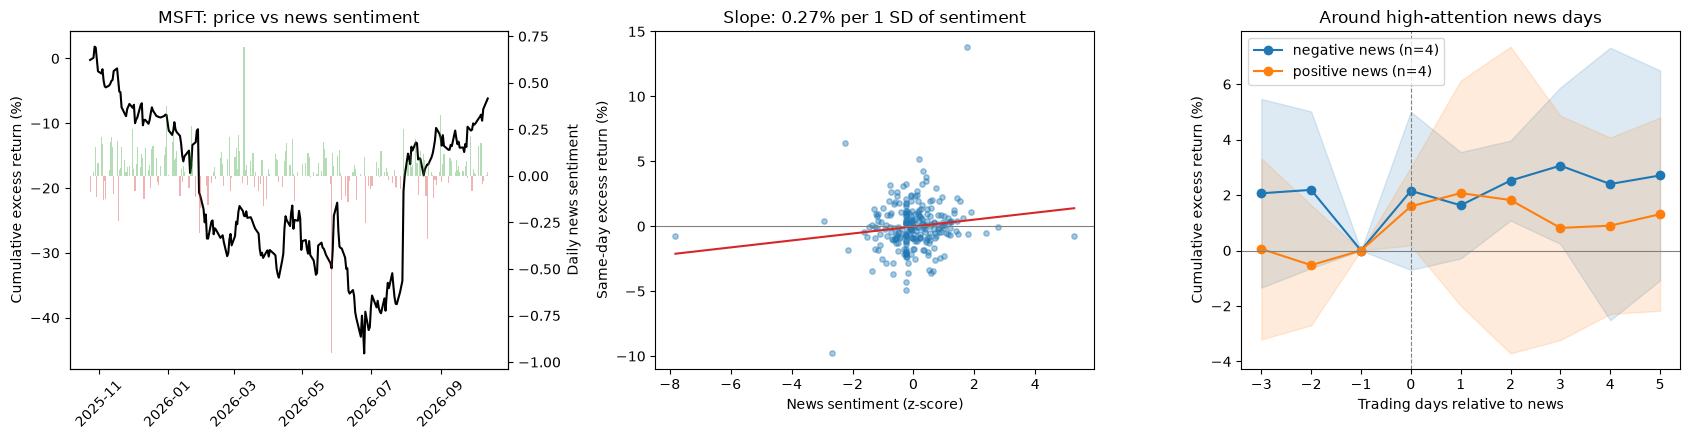

In [17]:
def plot_ticker(ticker: str):
    data = df[df["ticker"] == ticker].set_index("trade_date")
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

    # 1. przebieg w czasie: skumulowany zwrot ponad rynek i dzienny sentyment
    ax = axes[0]
    ax.plot(data.index, data["excess_pct"].cumsum(), color="black")
    ax.set_ylabel("Cumulative excess return (%)")
    ax2 = ax.twinx()
    colors = np.where(data["sent"] >= 0, "tab:green", "tab:red")
    ax2.bar(data.index, data["sent"], color=colors, alpha=0.35, width=1)
    ax2.set_ylabel("Daily news sentiment")
    ax.set_title(f"{ticker}: price vs news sentiment")
    ax.tick_params(axis="x", rotation=45)

    # 2. ten sam dzień: sentyment a zwrot
    ax = axes[1]
    ax.scatter(data["sent_z"], data["excess_pct"], alpha=0.4, s=15)
    slope, intercept = np.polyfit(data["sent_z"], data["excess_pct"], 1)
    xs = np.linspace(data["sent_z"].min(), data["sent_z"].max(), 50)
    ax.plot(xs, intercept + slope * xs, color="tab:red")
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_xlabel("News sentiment (z-score)")
    ax.set_ylabel("Same-day excess return (%)")
    ax.set_title(f"Slope: {slope:.2f}% per 1 SD of sentiment")

    # 3. zdarzenia: dni z nietypowo dużą liczbą newsów
    ax = axes[2]
    events = data[data["abn_news_z"] > 1.0]
    masks = {"negative news": events["sent_z"] < -0.5, "positive news": events["sent_z"] > 0.5}
    for label, mask in masks.items():
        part = events[mask][[f"ret_{k}" for k in WINDOW]].dropna()
        if len(part) < 3:
            continue
        cum = part.cumsum(axis=1)
        cum = cum.sub(cum["ret_-1"], axis=0)
        mean = cum.mean()
        se = cum.std() / np.sqrt(len(cum))
        line, = ax.plot(WINDOW, mean.values, marker="o", label=f"{label} (n={len(cum)})")
        ax.fill_between(WINDOW, (mean - 1.96 * se).values, (mean + 1.96 * se).values,
                        color=line.get_color(), alpha=0.15)
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.axvline(0, color="grey", linestyle="--", linewidth=0.8)
    ax.set_xlabel("Trading days relative to news")
    ax.set_ylabel("Cumulative excess return (%)")
    ax.set_title("Around high-attention news days")
    ax.legend()

    plt.tight_layout()
    return fig


fig = plot_ticker(TICKER)
fig.savefig(docs / f"news_{TICKER.lower()}.png", dpi=150)
plt.show()

In [18]:
from sqlalchemy import text
from transform.daily_features import assign_session
from transform.news_sentiment import MODEL

ALIASES = {
    "AAPL": ["Apple", "AAPL"], "MSFT": ["Microsoft", "MSFT"], "NVDA": ["Nvidia", "NVDA"],
    "JPM": ["JPMorgan", "JPM"], "BAC": ["Bank of America", "BofA", "BAC"], "GS": ["Goldman", "GS"],
    "O": ["Realty Income"], "NEE": ["NextEra", "NEE"], "DUK": ["Duke Energy", "DUK"],
    "GME": ["GameStop", "GME"], "AMC": ["AMC"],
}

NEWS_QUERY = text("""
    SELECT n.published_at, n.headline, s.score
    FROM raw.finnhub_news n
    JOIN features.news_sentiment s ON s.news_id = n.news_id AND s.model = :model
    WHERE n.ticker = :ticker
""")

# pełny kalendarz sesji, żeby newsy przypisać tak samo jak w pipeline
trading_days = pd.DatetimeIndex(
    pd.read_sql("SELECT DISTINCT trade_date FROM marts.daily_features ORDER BY 1",
                get_engine(), parse_dates=["trade_date"])["trade_date"]
)


def relevant_sentiment(ticker: str) -> tuple[pd.DataFrame, float]:
    news = pd.read_sql(NEWS_QUERY, get_engine(), params={"model": MODEL, "ticker": ticker})
    pattern = r"\b(?:" + "|".join(ALIASES[ticker]) + r")\b"
    news["relevant"] = news["headline"].str.contains(pattern, case=False, regex=True)
    news["trade_date"] = assign_session(news["published_at"], trading_days)

    daily = news[news["relevant"]].groupby("trade_date")["score"].agg(sent_rel="mean", news_rel="size")

    return daily, news["relevant"].mean()


daily_rel, share = relevant_sentiment(TICKER)
data = df[df["ticker"] == TICKER].merge(daily_rel, left_on="trade_date", right_index=True, how="left")
data["sent_rel"] = data["sent_rel"].fillna(0)
data["sent_rel_z"] = (data["sent_rel"] - data["sent_rel"].mean()) / data["sent_rel"].std()

print(f"{TICKER}: {share:.0%} nagłówków wymienia spółkę")
pd.concat({
    "all headlines": fit_one(data, "excess_pct", ["sent_z"]),
    "company in headline": fit_one(data, "excess_pct", ["sent_rel_z"]),
}).round(3)

MSFT: 28% nagłówków wymienia spółkę


,,beta,low,high,p_value,n
all headlines,sent_z,0.268,-0.078,0.613,0.129,243
company in headline,sent_rel_z,0.318,0.036,0.599,0.027,243


In [19]:
rows = []
for ticker in GROUPS:
    daily_rel, share = relevant_sentiment(ticker)
    data = df[df["ticker"] == ticker].merge(daily_rel, left_on="trade_date", right_index=True, how="left")
    data["sent_rel"] = data["sent_rel"].fillna(0)
    data["sent_rel_z"] = (data["sent_rel"] - data["sent_rel"].mean()) / data["sent_rel"].std()

    all_news = fit_one(data, "excess_pct", ["sent_z"]).iloc[0]
    relevant = fit_one(data, "excess_pct", ["sent_rel_z"]).iloc[0]
    rows.append({
        "ticker": ticker,
        "group": GROUPS[ticker],
        "share_relevant": share,
        "beta_all": all_news["beta"],
        "p_all": all_news["p_value"],
        "beta_relevant": relevant["beta"],
        "p_relevant": relevant["p_value"],
    })

relevance = pd.DataFrame(rows).set_index("ticker")
relevance.round(3)

,group,share_relevant,beta_all,p_all,beta_relevant,p_relevant
ticker,,,,,,
AAPL,Big tech,0.403,0.243,0.035,0.242,0.040
MSFT,Big tech,0.276,0.268,0.129,0.318,0.027
NVDA,Big tech,0.243,0.244,0.257,0.161,0.365
JPM,Banks,0.340,0.227,0.005,0.158,0.028
BAC,Banks,0.472,0.120,0.156,0.051,0.445
GS,Banks,0.418,0.292,0.008,0.231,0.013
O,Rate proxies,0.349,-0.100,0.199,0.025,0.737
NEE,Rate proxies,0.481,0.141,0.059,0.190,0.013
DUK,Rate proxies,0.523,0.053,0.535,0.113,0.163
